<a href="https://colab.research.google.com/github/THE5NEON/Python-Labs/blob/main/%D0%9B%D0%A010_%D0%A2%D0%BE%D1%87%D0%B5%D0%BD%D1%8E%D0%BA_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Точенюк Ярослав  
**Група:** 4-9  
**Дата:** 24.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras import layers, regularizers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
from IPython.display import display
from pathlib import Path
SEED = 42
keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: []


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
for name, arr in [('x_train', x_train), ('y_train', y_train), ('x_test', x_test), ('y_test', y_test)]:
    print(name, arr.shape)
assert x_train.shape[1:] == (28, 28) and len(np.unique(y_train)) == 10

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
x_train (60000, 28, 28)
y_train (60000,)
x_test (10000, 28, 28)
y_test (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

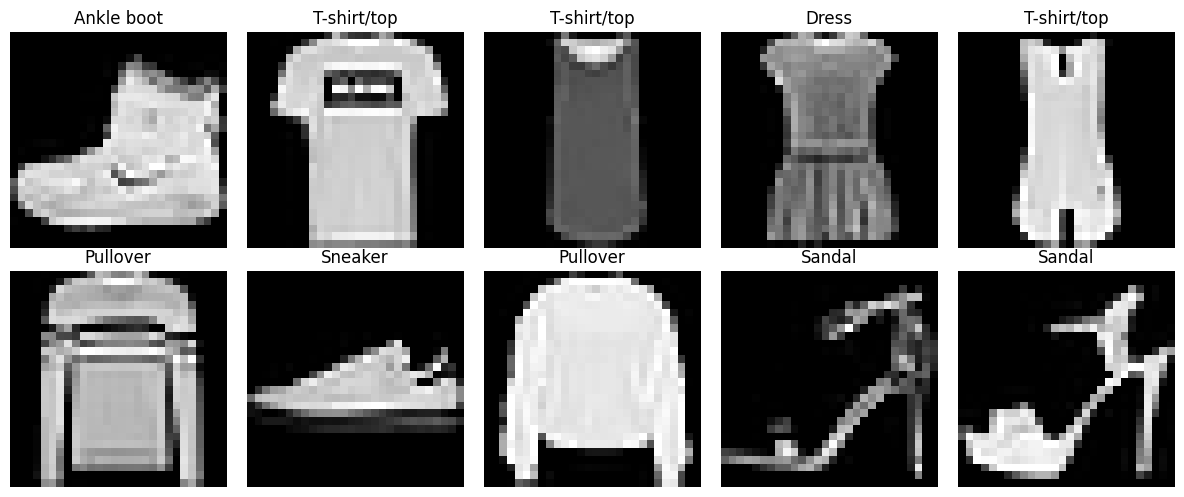

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap='gray')
    ax.set_title(class_names[y_train[i]])
    ax.axis('off')
plt.tight_layout(); plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
for name, arr in [('train', x_train), ('test', x_test)]:
    print(name, arr.dtype, arr.min(), arr.max())
    assert 0 <= arr.min() <= arr.max() <= 1
x_fit, x_val, y_fit, y_val = train_test_split(x_train, y_train, test_size=0.15, random_state=SEED, stratify=y_train)
print('Навчання:', x_fit.shape, 'Валідація:', x_val.shape)

train float32 0.0 1.0
test float32 0.0 1.0
Навчання: (51000, 28, 28) Валідація: (9000, 28, 28)


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

**Обґрунтування:** 512, 256 і 128 нейронів поступово стискають представлення ознак; Dropout 0,2 зменшує перенавчання, Adam із початковою швидкістю 0,001 є помірним вибором. Остаточні ваги обираються за валідаційною функцією втрат.

In [5]:
model = keras.Sequential([
    keras.Input(shape=(28, 28)), layers.Flatten(),
    layers.Dense(512, activation='relu'), layers.Dropout(0.2),
    layers.Dense(256, activation='relu'), layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
], name='fashion_baseline')
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
def make_callbacks():
    return [EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)]
history = model.fit(x_fit, y_fit, validation_data=(x_val, y_val), epochs=40, batch_size=128, callbacks=make_callbacks(), verbose=2)

Epoch 1/40
399/399 - 10s - 25ms/step - accuracy: 0.7979 - loss: 0.5601 - val_accuracy: 0.8586 - val_loss: 0.3829 - learning_rate: 0.0010
Epoch 2/40
399/399 - 12s - 30ms/step - accuracy: 0.8534 - loss: 0.4032 - val_accuracy: 0.8744 - val_loss: 0.3457 - learning_rate: 0.0010
Epoch 3/40
399/399 - 12s - 29ms/step - accuracy: 0.8665 - loss: 0.3640 - val_accuracy: 0.8767 - val_loss: 0.3287 - learning_rate: 0.0010
Epoch 4/40
399/399 - 18s - 45ms/step - accuracy: 0.8729 - loss: 0.3419 - val_accuracy: 0.8803 - val_loss: 0.3202 - learning_rate: 0.0010
Epoch 5/40
399/399 - 7s - 17ms/step - accuracy: 0.8788 - loss: 0.3254 - val_accuracy: 0.8836 - val_loss: 0.3127 - learning_rate: 0.0010
Epoch 6/40
399/399 - 16s - 39ms/step - accuracy: 0.8859 - loss: 0.3093 - val_accuracy: 0.8843 - val_loss: 0.3082 - learning_rate: 0.0010
Epoch 7/40
399/399 - 19s - 49ms/step - accuracy: 0.8879 - loss: 0.3000 - val_accuracy: 0.8872 - val_loss: 0.3046 - learning_rate: 0.0010
Epoch 8/40
399/399 - 12s - 30ms/step - acc

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
model.summary()
print('Кількість шарів:', len(model.layers))
print('Параметрів:', model.count_params())

Model: "fashion_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,702,304 (6.49 MB)

 Trainable params: 567,434 (2.16 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,134,870 (4.33 MB)

Кількість шарів: 7
Параметрів: 567434


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
model_path = Path('fashion_mnist_baseline.keras')
model.save(model_path)
assert model_path.is_file()
print('Збережено:', model_path.resolve())

Збережено: /content/fashion_mnist_baseline.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

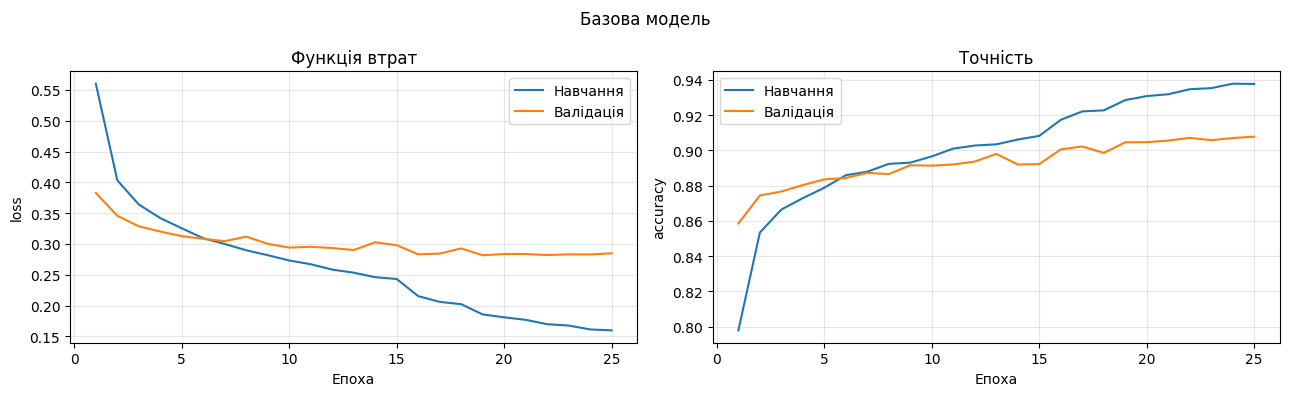

In [9]:
def plot_history(hist, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metric, caption in zip(axes, ['loss','accuracy'], ['Функція втрат','Точність']):
        epochs = range(1, len(hist.history[metric])+1)
        ax.plot(epochs, hist.history[metric], label='Навчання')
        ax.plot(epochs, hist.history['val_'+metric], label='Валідація')
        ax.set(xlabel='Епоха', ylabel=metric, title=caption)
        ax.legend(); ax.grid(alpha=.3)
    fig.suptitle(title); plt.tight_layout(); plt.show()
plot_history(history, 'Базова модель')

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
probs = model.predict(x_test, verbose=0)
y_pred = probs.argmax(axis=1)
assert probs.shape == (len(y_test), 10) and np.allclose(probs.sum(axis=1), 1, atol=1e-5)
print(f'Test loss: {test_loss:.4f}; accuracy: {test_accuracy:.4f}')
print(classification_report(y_test, y_pred, labels=np.arange(10), target_names=class_names, zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))
errors = cm.sum(axis=1)-cm.diagonal()
hard_classes = [class_names[i] for i in np.argsort(errors)[-3:][::-1]]
print('Найбільше помилок:', ', '.join(hard_classes))
print('Поріг 0,87:', 'досягнуто' if test_accuracy >= .87 else 'не досягнуто')

Test loss: 0.3063; accuracy: 0.8971
              precision    recall  f1-score   support

 T-shirt/top       0.84      0.86      0.85      1000
     Trouser       0.99      0.98      0.98      1000
    Pullover       0.79      0.85      0.82      1000
       Dress       0.89      0.90      0.90      1000
        Coat       0.81      0.81      0.81      1000
      Sandal       0.98      0.97      0.98      1000
       Shirt       0.77      0.68      0.72      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.97      0.96      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000

Найбільше помилок: Shirt, Coat, Pullover
Поріг 0,87: досягнуто


### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

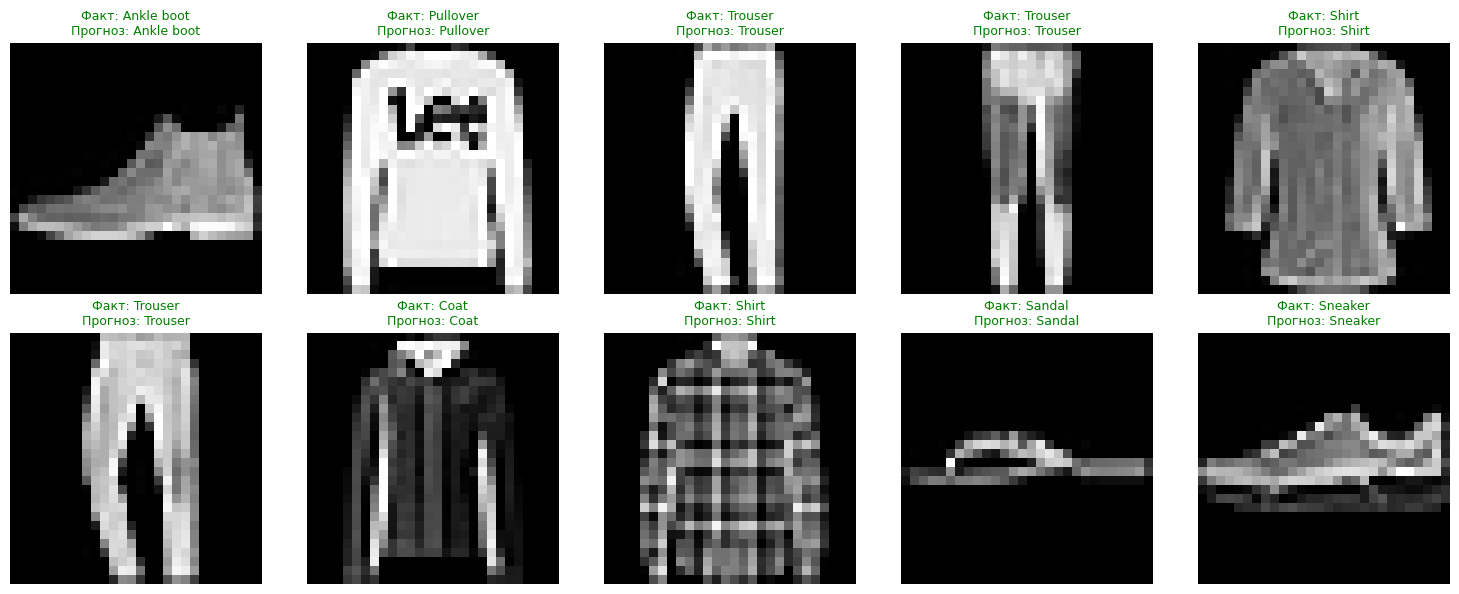

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i], cmap='gray'); ax.axis('off')
    ax.set_title(f'Факт: {class_names[y_test[i]]}\nПрогноз: {class_names[y_pred[i]]}', color='green' if y_test[i]==y_pred[i] else 'red', fontsize=9)
plt.tight_layout(); plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
Числовий висновок автоматично формується в наступній комірці за фактичними результатами.

In [12]:
print(f'Базова accuracy = {test_accuracy:.4f}. Вимогу 0,87 '+('виконано.' if test_accuracy >= .87 else 'не виконано.'))
print('Класи з найбільшою кількістю помилок:', ', '.join(hard_classes))

Базова accuracy = 0.8971. Вимогу 0,87 виконано.
Класи з найбільшою кількістю помилок: Shirt, Coat, Pullover


# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [13]:
import sys, subprocess, importlib.util
if importlib.util.find_spec('keras_tuner') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'keras-tuner'])
import keras_tuner as kt
from keras_tuner import RandomSearch
from keras.layers import Dense, Flatten, Dropout
from keras.regularizers import l2

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [14]:
assert len(x_fit)+len(x_val) == len(x_train)
assert len(x_test) == len(y_test)
print('Для пошуку:', x_fit.shape, x_val.shape)
print('Тестова вибірка зарезервована для фінальної оцінки:', x_test.shape)

Для пошуку: (51000, 28, 28) (9000, 28, 28)
Тестова вибірка зарезервована для фінальної оцінки: (10000, 28, 28)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [15]:
def build_model(hp):
    net = keras.Sequential([keras.Input(shape=(28,28)), Flatten()])
    num_layers = hp.Int('num_layers', min_value=1, max_value=3)
    for i in range(num_layers):
        units = hp.Int(f'units_{i}', min_value=32, max_value=512, step=32)
        net.add(Dense(units, activation='relu', kernel_regularizer=l2(1e-4)))
        net.add(Dropout(0.2))
    net.add(Dense(10, activation='softmax'))
    lr = hp.Choice('learning_rate', values=[0.01, 0.001, 0.0001])
    net.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return net

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [16]:
tuner = RandomSearch(build_model, objective='val_accuracy', max_trials=3, executions_per_trial=1, directory='keras_tuner_results', project_name='fashion_mnist_lr10', overwrite=True, seed=SEED)
tuner.search_space_summary()

Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [17]:
tuner.search(x_fit, y_fit, validation_data=(x_val,y_val), epochs=30, batch_size=128, callbacks=make_callbacks(), verbose=2)
best_hp = tuner.get_best_hyperparameters(1)[0]
print('Найкращі гіперпараметри:', best_hp.values)
tuner.results_summary()
keras.utils.set_random_seed(SEED)
best_model = build_model(best_hp)
best_model.summary()
best_history = best_model.fit(x_fit, y_fit, validation_data=(x_val,y_val), epochs=40, batch_size=128, callbacks=make_callbacks(), verbose=2)
best_model.save('fashion_mnist_tuned.keras')

Trial 3 Complete [00h 01m 59s]
val_accuracy: 0.8946666717529297

Best val_accuracy So Far: 0.906000018119812
Total elapsed time: 00h 06m 53s
Найкращі гіперпараметри: {'num_layers': 1, 'units_0': 480, 'learning_rate': 0.001, 'units_1': 288}
Results summary
Results in keras_tuner_results/fashion_mnist_lr10
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 1 summary
Hyperparameters:
num_layers: 1
units_0: 480
learning_rate: 0.001
units_1: 288
Score: 0.906000018119812

Trial 2 summary
Hyperparameters:
num_layers: 1
units_0: 256
learning_rate: 0.01
units_1: 512
Score: 0.8946666717529297

Trial 0 summary
Hyperparameters:
num_layers: 2
units_0: 32
learning_rate: 0.001
units_1: 32
Score: 0.8778889179229736


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 381,610 (1.46 MB)

 Trainable params: 381,610 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
399/399 - 6s - 15ms/step - accuracy: 0.8098 - loss: 0.6002 - val_accuracy: 0.8611 - val_loss: 0.4463 - learning_rate: 0.0010
Epoch 2/40
399/399 - 6s - 16ms/step - accuracy: 0.8552 - loss: 0.4574 - val_accuracy: 0.8721 - val_loss: 0.4116 - learning_rate: 0.0010
Epoch 3/40
399/399 - 5s - 12ms/step - accuracy: 0.8674 - loss: 0.4206 - val_accuracy: 0.8773 - val_loss: 0.3962 - learning_rate: 0.0010
Epoch 4/40
399/399 - 5s - 13ms/step - accuracy: 0.8748 - loss: 0.3982 - val_accuracy: 0.8770 - val_loss: 0.3874 - learning_rate: 0.0010
Epoch 5/40
399/399 - 6s - 15ms/step - accuracy: 0.8807 - loss: 0.3828 - val_accuracy: 0.8832 - val_loss: 0.3801 - learning_rate: 0.0010
Epoch 6/40
399/399 - 5s - 12ms/step - accuracy: 0.8833 - loss: 0.3748 - val_accuracy: 0.8876 - val_loss: 0.3668 - learning_rate: 0.0010
Epoch 7/40
399/399 - 6s - 16ms/step - accuracy: 0.8863 - loss: 0.3646 - val_accuracy: 0.8857 - val_loss: 0.3658 - learning_rate: 0.0010
Epoch 8/40
399/399 - 5s - 13ms/step - accuracy: 

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Test loss: 0.3407; accuracy: 0.8976


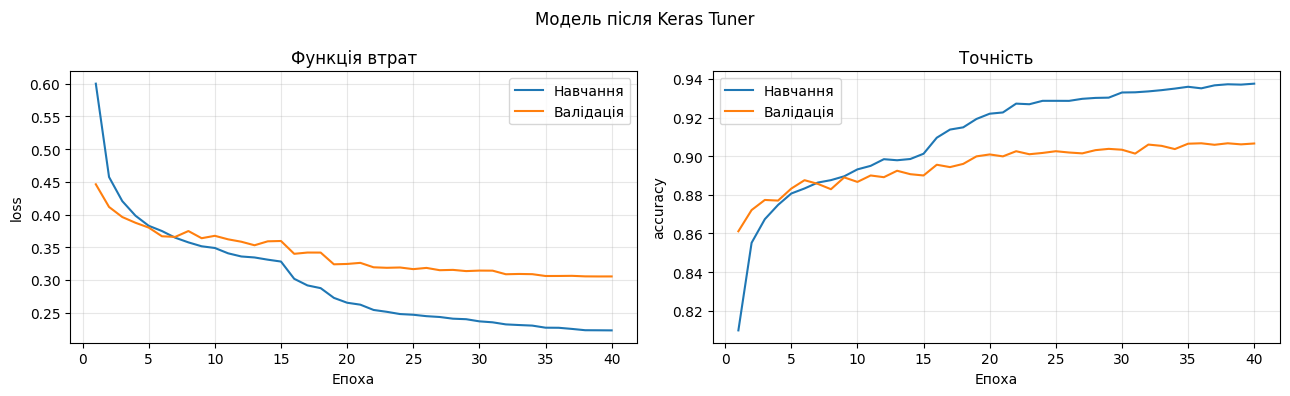

In [18]:
tuned_loss, tuned_accuracy = best_model.evaluate(x_test, y_test, verbose=0)
print(f'Test loss: {tuned_loss:.4f}; accuracy: {tuned_accuracy:.4f}')
plot_history(best_history, 'Модель після Keras Tuner')

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів |  |  |
| Кількість нейронів |  |  |
| Швидкість навчання |  |  |
| Точність на тестовій вибірці (accuracy) |  |  |
| Втрати на тестовій вибірці (loss) |  |  |
| Кількість епох навчання |  |  |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
Підсумкова таблиця та відповіді автоматично формуються нижче після навчання обох моделей.

In [19]:
num = best_hp.get('num_layers')
units = [best_hp.get(f'units_{i}') for i in range(num)]
comparison = pd.DataFrame({'Показник':['Кількість прихованих шарів','Кількість нейронів','Швидкість навчання (початкова)','Test accuracy','Test loss','Кількість епох навчання'], 'Базова модель':[3,'512, 256, 128',0.001,round(test_accuracy,4),round(test_loss,4),len(history.epoch)], 'Keras Tuner':[num,', '.join(map(str,units)),best_hp.get('learning_rate'),round(tuned_accuracy,4),round(tuned_loss,4),len(best_history.epoch)]})
display(comparison)
print('1. Поріг 0,87:', 'досягнуто' if test_accuracy >= .87 else 'не досягнуто')
delta=tuned_accuracy-test_accuracy
print(f'2. Зміна точності: {delta*100:+.2f} в.п.; '+('покращення' if delta>0 else 'без покращення'))
print(f'3. Найкраща конфігурація за val_accuracy: {num} шарів, нейрони {units}, LR={best_hp.get("learning_rate")}. Результати залежать від ініціалізації ваг, порядку батчів, випадкового пошуку та обладнання.')
print('4. Найскладніші класи базової моделі:', ', '.join(hard_classes), '. Подібні фасони одягу можуть мати схожі контури.')
print('Примітка: loss моделі після Tuner включає штраф L2, тому значення loss не цілком еквівалентні.')

,Показник,Базова модель,Keras Tuner
0,Кількість прихованих шарів,3,1
1,Кількість нейронів,"512, 256, 128",480
2,Швидкість навчання (початкова),0.001,0.001
3,Test accuracy,0.8971,0.8976
4,Test loss,0.3063,0.3407
5,Кількість епох навчання,25,40


1. Поріг 0,87: досягнуто
2. Зміна точності: +0.05 в.п.; покращення
3. Найкраща конфігурація за val_accuracy: 1 шарів, нейрони [480], LR=0.001. Результати залежать від ініціалізації ваг, порядку батчів, випадкового пошуку та обладнання.
4. Найскладніші класи базової моделі: Shirt, Coat, Pullover . Подібні фасони одягу можуть мати схожі контури.
Примітка: loss моделі після Tuner включає штраф L2, тому значення loss не цілком еквівалентні.
